# Stabilità temporale delle metriche

Per ogni metrica, correlazione fra i valori dell'anno $t$ e quelli dell'anno $t+\tau$ (sui paesi / prodotti presenti in entrambi gli anni),
mediata su tutti gli anni di partenza, al variare del ritardo $\tau$. Una metrica stabile decade lentamente.

- paesi: F della fitness estesa, dell'ECI esteso, della fitness classica, ECI classico
- prodotti: Q delle due metriche estese, complessità della fitness classica, PCI

Pearson sulle metriche trasformate (log per quelle positive tipo fitness), Spearman sui ranghi.
Metriche da `results/econometria/metriche/4_digits/` (via `src/storage.py`) (tutti gli anni 2002–2024). Figure in `plots/econometria/stabilita_temporale/`.

Il ritardo si indica con $\tau$ per non confonderlo con la complessità intrinseca $\Delta$ delle metriche estese.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.storage import load_metrics_long
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()

# famiglie di colore: fitness = blu, ECI = arancio; estesa = scura, classica = chiara
METRIC_COLOR = {"extended_fitness": "#0072B2", "fitness": "#56B4E9", "extended_eci": "#D55E00", "eci": "#E69F00"}
METRIC_LABEL = {"extended_fitness": "Extended Fitness", "fitness": "Fitness", "extended_eci": "Extended ECI", "eci": "ECI"}

## Configurazione

In [2]:
RES = 4
COUNTRY_METRICS = {"extended_fitness": ("extended_fitness", "F", "log"), "extended_eci": ("extended_eci", "F", "log"),
                   "fitness": ("fitness", "F", "log"), "eci": ("eci", "ECI", "raw")}
PRODUCT_METRICS = {"extended_fitness": ("extended_fitness", "Q", "log"), "extended_eci": ("extended_eci", "Q", "log"),
                   "fitness": ("fitness", "Q", "log"), "eci": ("eci", "PCI", "raw")}
HEATMAP_METRIC = "extended_fitness"

SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "econometria" / "stabilita_temporale" 

## Correlazioni fra anni

In [3]:
def wide(df, key, metric, variable, tr):
    s = df[(df.metric == metric) & (df.variable == variable)].pivot(index=key, columns="year", values="value")
    if tr == "log":
        s = np.log(s.where(s > 0))
    return s

def corr_matrix(w, method):
    years = w.columns
    M = pd.DataFrame(np.nan, index=years, columns=years)
    for i, a in enumerate(years):
        for b in years[i:]:
            ok = w[a].notna() & w[b].notna()
            M.loc[a, b] = M.loc[b, a] = w.loc[ok, a].corr(w.loc[ok, b], method=method)
    return M

def by_lag(M):
    y = M.index.to_numpy()
    lags = range(1, len(y))
    return pd.Series({L: np.nanmean([M.iloc[i, i + L] for i in range(len(y) - L)]) for L in lags})

paesi = load_metrics_long(RES, "country")
prodotti = load_metrics_long(RES, "product")

stab = {}
for level, df, key, spec in (("paesi", paesi, "country", COUNTRY_METRICS), ("prodotti", prodotti, "product", PRODUCT_METRICS)):
    for k, (metric, variable, tr) in spec.items():
        w = wide(df, key, metric, variable, tr)
        for method in ("pearson", "spearman"):
            M = corr_matrix(w, method)
            stab[(level, k, method)] = {"matrix": M, "lag": by_lag(M)}

summary = pd.DataFrame({(lvl, k, m): v["lag"] for (lvl, k, m), v in stab.items()})
summary.loc[[1, 5, 10, 20]].T.round(3)

1      5      10     20
paesi    extended_fitness pearson   0.953  0.914  0.876  0.829
                          spearman  0.964  0.928  0.901  0.856
         extended_eci     pearson   0.899  0.839  0.782  0.699
                          spearman  0.909  0.851  0.801  0.705
         fitness          pearson   0.776  0.680  0.574  0.658
                          spearman  0.969  0.937  0.916  0.880
         eci              pearson   0.944  0.903  0.866  0.784
                          spearman  0.947  0.910  0.879  0.791
prodotti extended_fitness pearson   0.926  0.847  0.823  0.807
                          spearman  0.933  0.884  0.864  0.849
         extended_eci     pearson   0.988  0.956  0.936  0.869
                          spearman  0.996  0.991  0.989  0.981
         fitness          pearson   0.649  0.500  0.441  0.516
                          spearman  0.801  0.744  0.713  0.650
         eci              pearson   0.943  0.898  0.875  0.815
                          spearman  0.946  0.901  0.879  0.816

## Correlazione in funzione del ritardo

Nel grafico solo Spearman (correlazione di rango, standard per la stabilità degli ordinamenti): la Pearson della fitness
classica è dominata dai pochi paesi/prodotti con fitness quasi nulla, il cui log fluttua molto. I valori Pearson sono nella tabella sopra.

paesi


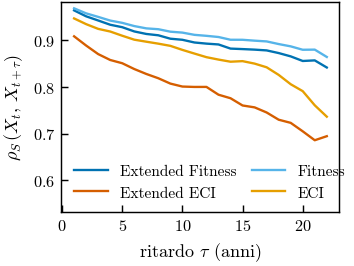

prodotti


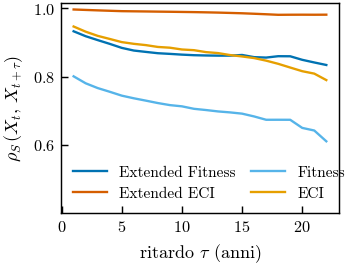

In [4]:
LAG_METHOD = "spearman"

def plot_lag(level):
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    keys = COUNTRY_METRICS if level == "paesi" else PRODUCT_METRICS
    for k in keys:
        s = stab[(level, k, LAG_METHOD)]["lag"]
        ax.plot(s.index, s.values, color=METRIC_COLOR[k], label=METRIC_LABEL[k])
    ax.set_xlabel(r"ritardo $\tau$ (anni)")
    ax.set_ylabel(r"$\rho_S\,(X_t,\, X_{t+\tau})$")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.45 * (hi - lo), hi)          # spazio per la legenda in basso
    ax.legend(loc="lower left", ncol=2, columnspacing=1.0)
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"stabilita_ritardo_{level}")
    plt.show()

for level in ("paesi", "prodotti"):
    print(level)
    plot_lag(level)

## Matrice anno × anno (Spearman)

paesi Extended Fitness


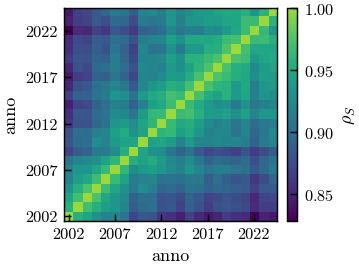

prodotti Extended Fitness


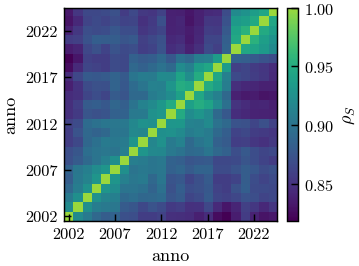

In [5]:
for level in ("paesi", "prodotti"):
    M = stab[(level, HEATMAP_METRIC, "spearman")]["matrix"]
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    im = ax.imshow(M.values, cmap=SEQ_CMAP, vmin=np.nanmin(M.values), vmax=1, origin="lower")
    ticks = np.arange(0, len(M), 5)
    ax.set_xticks(ticks); ax.set_xticklabels(M.index[ticks])
    ax.set_yticks(ticks); ax.set_yticklabels(M.index[ticks])
    ax.set_xlabel("anno"); ax.set_ylabel("anno")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(r"$\rho_S$")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"matrice_anni_{HEATMAP_METRIC}_{level}")
    print(level, METRIC_LABEL[HEATMAP_METRIC])
    plt.show()

## Da dove vengono le fluttuazioni

Nelle metriche estese la complessità di un prodotto è $Q_p = CQ_p + \Delta_p$:
- $CQ_p = \alpha \sum_{p'} C_{p'p} Q_{p'}$, complessità degli input: $C$ è la stessa in tutti gli anni, quindi cambia solo attraverso le $Q$ degli input;
- $\Delta_p$, complessità intrinseca: è la $Q$ della fitness (o il PCI) calcolata sulla $M_{cp}$ dell'anno, e fluttua come la metrica classica.

Nelle figure dei componenti la linea tratteggiata è la metrica classica (senza input) per confronto.

Due verifiche:
1. **prodotti**: stabilità separata di $CQ$, $\Delta$ e $Q$, confrontata con la metrica classica;
2. **paesi**: $F_c = \sum_p M_{cp} Q_p$ cambia sia se cambiano le $Q$ sia se cambia il paniere di export $M_{cp}$.
   Si ricalcola $F$ tenendo le $Q$ fisse nel tempo (media sugli anni) e lasciando cambiare solo $M$:
   se la stabilità non cambia, le fluttuazioni dei paesi vengono dai panieri, non dalla complessità dei prodotti.

Extended Fitness


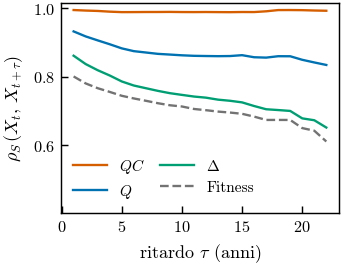

Extended ECI


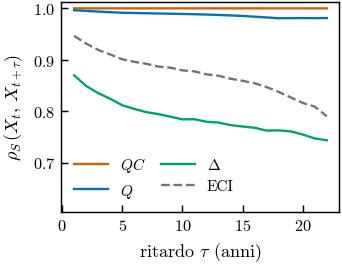

,metrica,CQ/Q medio,variazione di Q da CQ,variazione di Q da Delta
0,Extended Fitness,0.441,0.008,0.993
1,Extended ECI,0.361,0.012,0.980


In [6]:
COMPONENT_LABEL = {"CQ": r"$QC$", "Q": r"$Q$", "Delta": r"$\Delta$"}
CLASSIC = {"extended_fitness": "fitness", "extended_eci": "eci"}

rows = []
for algo in ("extended_fitness", "extended_eci"):
    W = {v: wide(prodotti, "product", algo, v, "raw") for v in ("Q", "CQ", "Delta")}
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    for v in ("CQ", "Q", "Delta"):
        s = by_lag(corr_matrix(W[v], "spearman"))
        ax.plot(s.index, s.values, color=PALETTE[v], label=COMPONENT_LABEL[v])
    k = CLASSIC[algo]
    s = stab[("prodotti", k, "spearman")]["lag"]
    ax.plot(s.index, s.values, ls="--", color="0.45", label=f"{METRIC_LABEL[k]}")
    ax.set_xlabel(r"ritardo $\tau$ (anni)")
    ax.set_ylabel(r"$\rho_S\,(X_t,\, X_{t+\tau})$")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.45 * (hi - lo), hi)
    ax.legend(loc="lower left", ncol=2, columnspacing=1.0)
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"stabilita_componenti_{algo}")
    print(METRIC_LABEL[algo])
    plt.show()

    # quota media di CQ in Q e quota della variazione anno su anno di Q dovuta a CQ e a Delta
    dC, dD = W["CQ"].diff(axis=1), W["Delta"].diff(axis=1)
    tot = (dC**2).sum().sum() + (dD**2).sum().sum() + 2 * (dC * dD).sum().sum()
    rows.append({"metrica": METRIC_LABEL[algo], "CQ/Q medio": (W["CQ"] / W["Q"]).mean().mean(),
                 "variazione di Q da CQ": (dC**2).sum().sum() / tot,
                 "variazione di Q da Delta": (dD**2).sum().sum() / tot})
pd.DataFrame(rows).round(3)

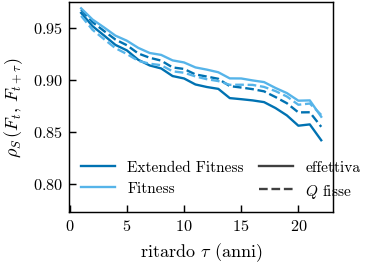

In [7]:
MCP = ROOT / "data" / "HS02_all_years" / f"{RES}_digits" / "alligned" / "binarized" / "Mcp_export"
YEARS = sorted(paesi.year.unique())
Ms = {y: pd.read_parquet(MCP / f"Mcp_export_alligned_Y{y}.parquet") for y in YEARS}

fig, ax = plt.subplots(figsize=figsize(*HALF))
for algo in ("extended_fitness", "fitness"):
    Qw = wide(prodotti, "product", algo, "Q", "raw")
    Qbar = (Qw / Qw.mean()).mean(axis=1)                     # Q di ogni prodotto, media sugli anni
    F_fix = pd.DataFrame({y: pd.Series(M.values @ Qbar.reindex(M.columns).fillna(0).values, index=M.index)
                          for y, M in Ms.items()})
    s = stab[("paesi", algo, "spearman")]["lag"]
    ax.plot(s.index, s.values, color=METRIC_COLOR[algo])
    s = by_lag(corr_matrix(F_fix, "spearman"))
    ax.plot(s.index, s.values, ls="--", color=METRIC_COLOR[algo])
ax.set_xlabel(r"ritardo $\tau$ (anni)")
ax.set_ylabel(r"$\rho_S\,(F_t,\, F_{t+\tau})$")
lo, hi = ax.get_ylim()
ax.set_ylim(lo - 0.45 * (hi - lo), hi)
# colore = metrica, stile = F effettiva / Q fisse nel tempo
two_part_legend(ax, [(METRIC_LABEL[a], METRIC_COLOR[a]) for a in ("extended_fitness", "fitness")],
                [("effettiva", "-", True), (r"$Q$ fisse", "--", False)],
                loc="lower left", ncol=2, columnspacing=1.0)
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / "stabilita_paesi_Q_fisse")
plt.show()

### Lettura

- **Prodotti**: $CQ$ è quasi costante ($\rho_S \approx 0.99$ anche a 20 anni), $\Delta$ fluttua quanto la metrica classica.
  Anche se $CQ$ pesa in media circa metà di $Q$, quasi tutta la *variazione* di $Q$ da un anno all'altro viene da $\Delta$:
  la metà stabile non si muove, ma il ranking dipende anche dall'altra metà, che si muove.
  Il risultato è intermedio: $Q$ estesa è molto più stabile della $Q$ classica ma meno di $CQ$.
  Per l'ECI esteso $CQ$ domina il ranking di $Q$, e infatti $Q$ è stabile quasi quanto $CQ$.
- **Paesi**: tenendo fisse le $Q$ la stabilità di $F$ resta praticamente la stessa: le fluttuazioni della fitness dei paesi
  vengono dai cambiamenti dei panieri di export ($M_{cp}$), non dalla complessità dei prodotti.
  Per questo aggiungere un termine stabile sui prodotti non rende più stabile la fitness dei paesi.